# I will use transfer learning for for this project

first I will train a CNN from strach on ESC50 Data and then freeze the parameters and then will train on GENRES_STEMS Data

In [ ]:
from helper.golbal_variables import *

In [2]:
import torch, torchaudio, numpy
print(torch.__version__)
print(torchaudio.__version__)
print(numpy.__version__)

2.2.2+cpu
2.2.2+cpu
1.26.4


## Exploring EC50 data

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd

In [4]:
esc50_df = pd.read_csv(ESC_50_MASTER/"meta/esc50.csv")

Files follow a specific pattern: {FOLD}-{CLIP_ID}-{TAKE}-{TARGET}.wav. The TARGET (0-49) is the class ID you are trying to predict.

In [5]:
esc50_df.shape

(2000, 7)

In [6]:
esc50_df.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


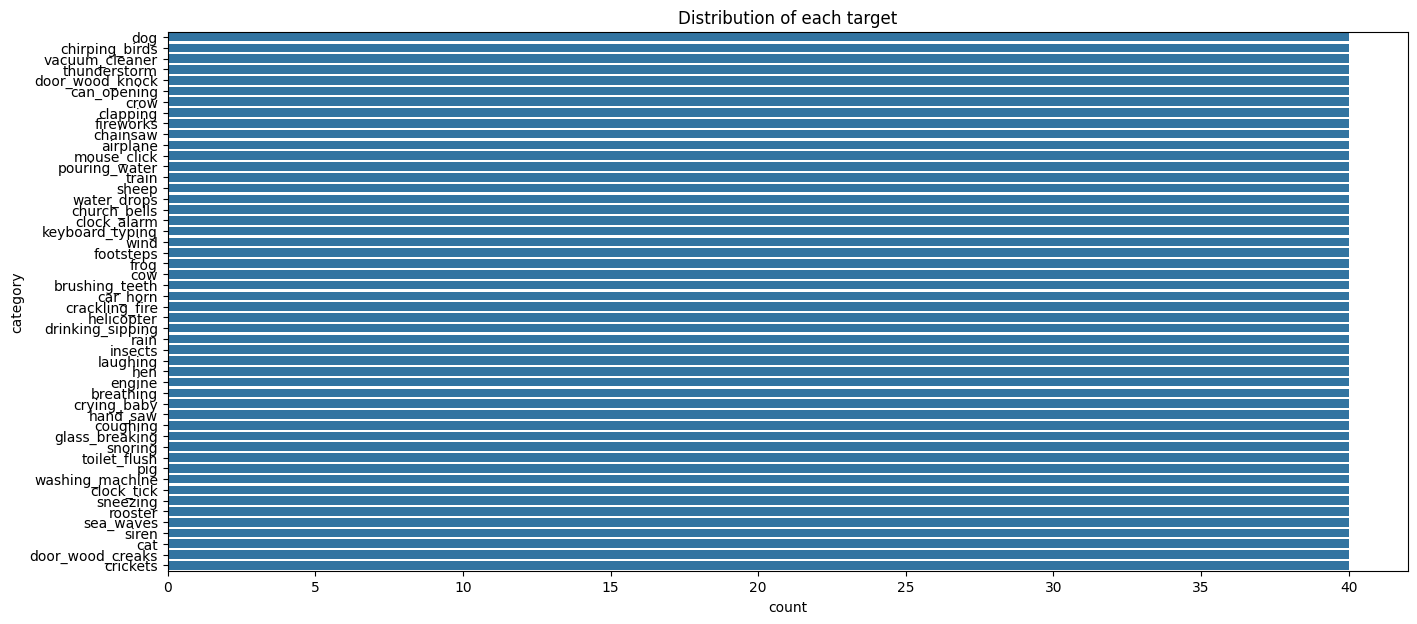

In [7]:
plt.figure(figsize=(16, 7))
sns.countplot(data=esc50_df, y="category")
plt.title("Distribution of each target")
plt.show()

All category have same distribution our data of ECS50 is balanced

## Checking wave forms

### Checking genres

In [2]:
from pathlib import Path
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
from IPython.display import display

def plot_each_wav(folder: Path):
    files = list(folder.glob("*.wav")) 
    
    if not files:
        print(f"No .wav files found in {folder}")
        return

    fig, axes = plt.subplots(len(files), 1, figsize=(14, 3 * len(files)), squeeze=False)
    axes = axes.flatten()

    for ax, filename in zip(axes, files):
        data, sample_rate = librosa.load(filename, sr=None)
        librosa.display.waveshow(data, sr=sample_rate, ax=ax)
        
        ax.set_title(filename.name)
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Amplitude")

    plt.tight_layout()
    plt.show()

    print("\nAudio Samples:\n")
    for filename in files:
        print(filename.name)
        display(ipd.Audio(str(filename)))
        print("-" * 60)

### BLUES

In [ ]:
# plot_each_wav(BLUES / "blues.00000")

### classical

In [ ]:
# plot_each_wav(CLASSICAL / "classical.00000")

## 

# Now let's train a model on ESC50 dataset

In [2]:
import torch
from helper.custom_dataloader import ESC50_DataLoader, GenreDataLoader
from torch.utils.data import DataLoader

from CNN_model.cnn_arch_for_esc50 import ESC50_CNN
from CNN_model.utils import cross_validation, train, test

import matplotlib.pyplot as plt
import librosa.display
from IPython.display import display
import IPython.display as ipd

### Checking if DataLoader is laoding data properly

In [4]:
dataset = ESC50_DataLoader(ESC_50_MASTER)
dataset.load_meta_data(ESC_50_MASTER/"meta/esc50.csv")

loader = DataLoader(dataset, batch_size=16, shuffle=True)

for x, y in loader:
    print(x.shape)
    print(y.shape)
    break

Loading metadata from file: data\ESC-50-master\meta\esc50.csv
torch.Size([16, 1, 256, 431])
torch.Size([16])


z:\dlgen-AI-project\.venv\Lib\site-packages\torchaudio\functional\functional.py:584: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (256) may be set too high. Or, the value for `n_freqs` (513) may be set too low.
  warnings.warn(


Checking if loader if giving correct spectrum

In [5]:
import matplotlib.pyplot as plt
import librosa.display
import torchaudio
from IPython.display import display
import IPython.display as ipd

def load_spectrum_waveform_foresc50(index):
    mel, label = dataset[index]
    mel = mel[0].detach().cpu().numpy()

    row = dataset.meta_data.iloc[index]
    file_path = dataset.audio_dir / row["filename"]

    waveform, sr = torchaudio.load(file_path)

    waveform = waveform.mean(dim=0)

    if sr != 22050:
        resampler = torchaudio.transforms.Resample(sr, 22050)
        waveform = resampler(waveform.unsqueeze(0)).squeeze(0)

    wave_np = waveform.detach().cpu().numpy()

    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    # WAVEFORM
    axes[0].plot(wave_np)
    axes[0].set_title("Waveform (Time Domain)")
    axes[0].set_xlabel("Samples")
    axes[0].set_ylabel("Amplitude")

    # MEL
    img = librosa.display.specshow(
        mel,
        sr=22050,
        hop_length=512,
        x_axis="time",
        y_axis="mel",
        ax=axes[1]
    )

    axes[1].set_title(f"Mel Spectrogram | Label: {label.item()}")
    fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

    plt.tight_layout()
    plt.show()

    display(ipd.Audio(str(file_path)))

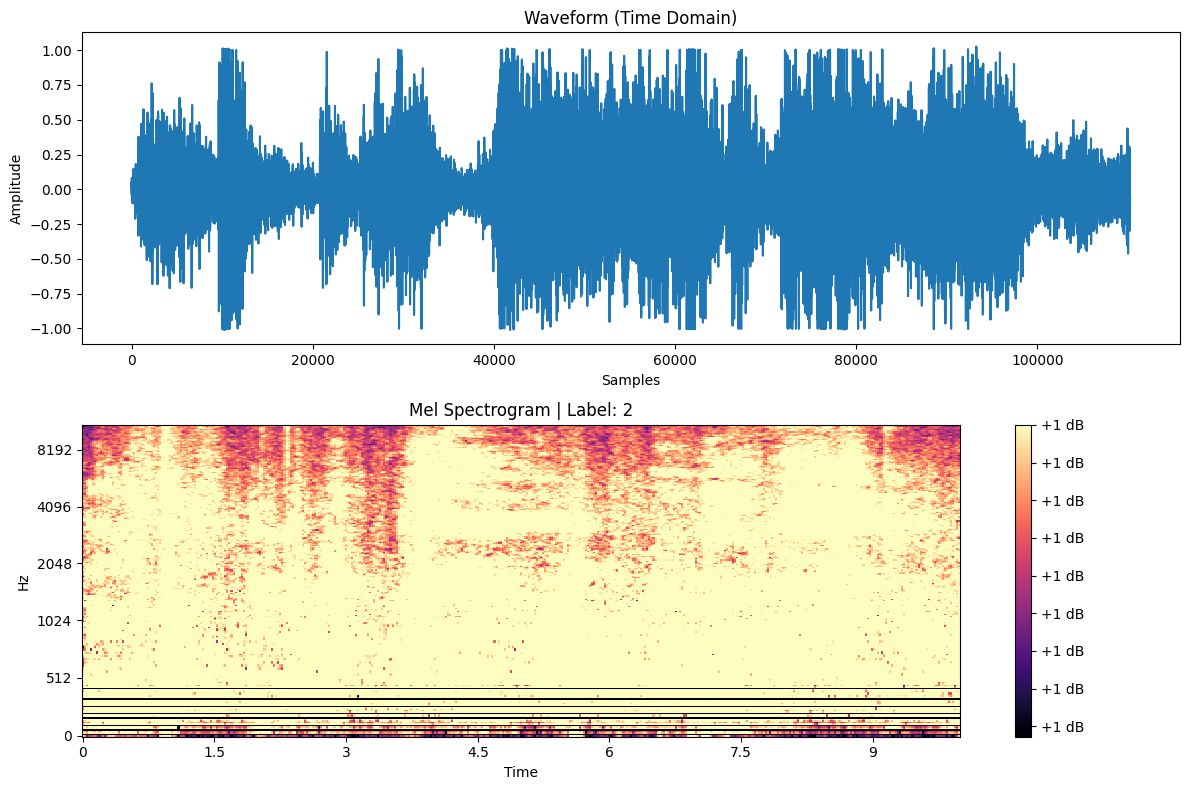

In [6]:
load_spectrum_waveform_foresc50(index=99)

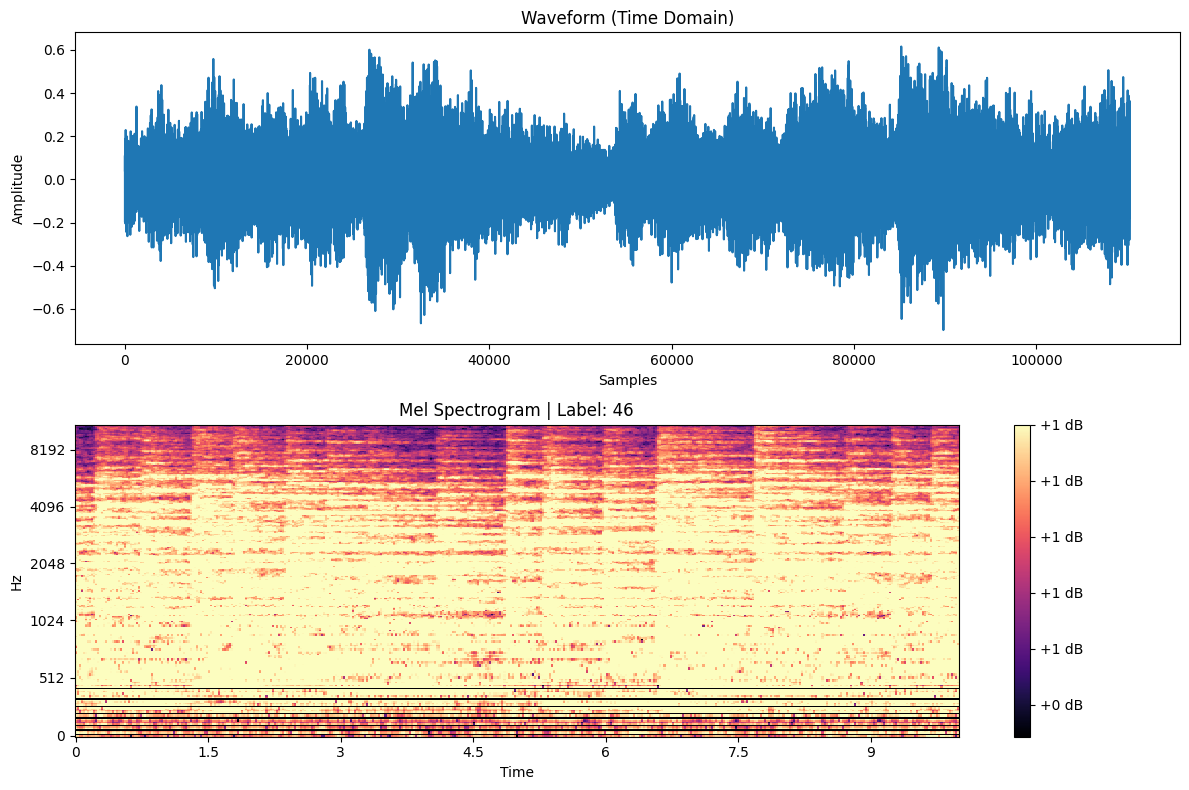

In [7]:
load_spectrum_waveform_foresc50(199)

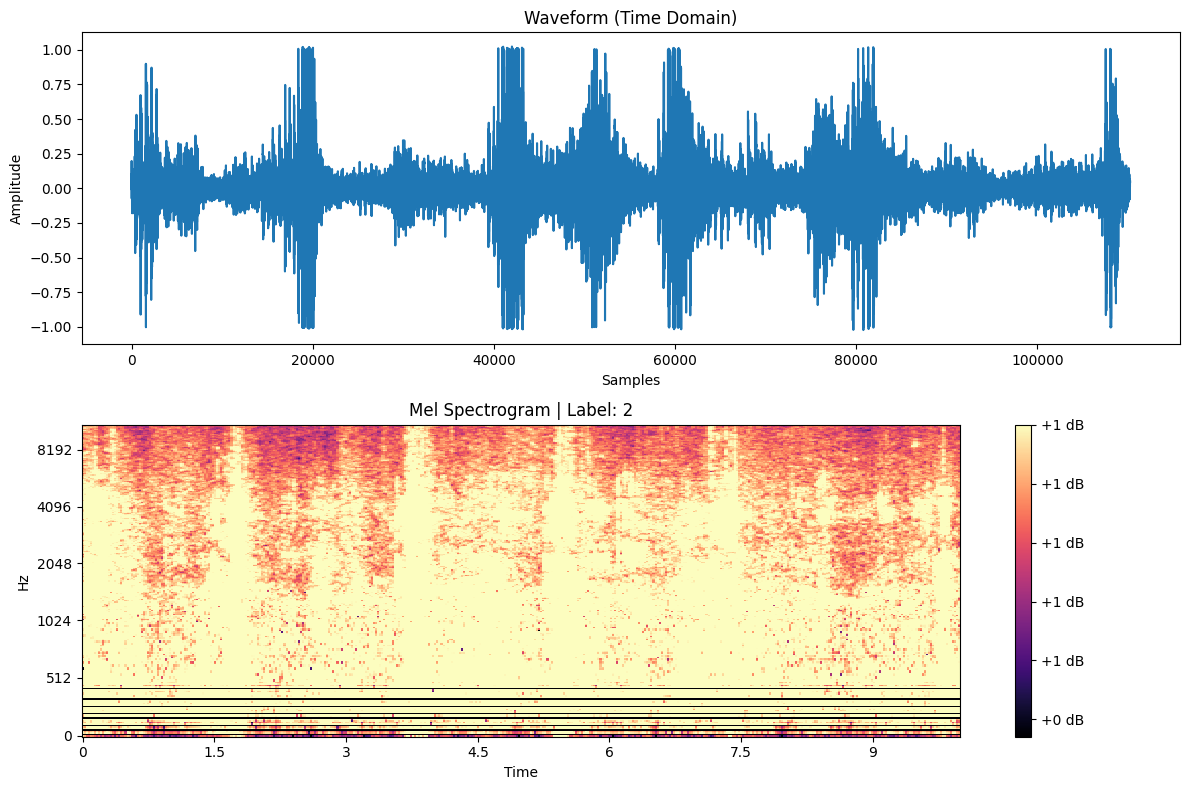

In [8]:
load_spectrum_waveform_foresc50(102)

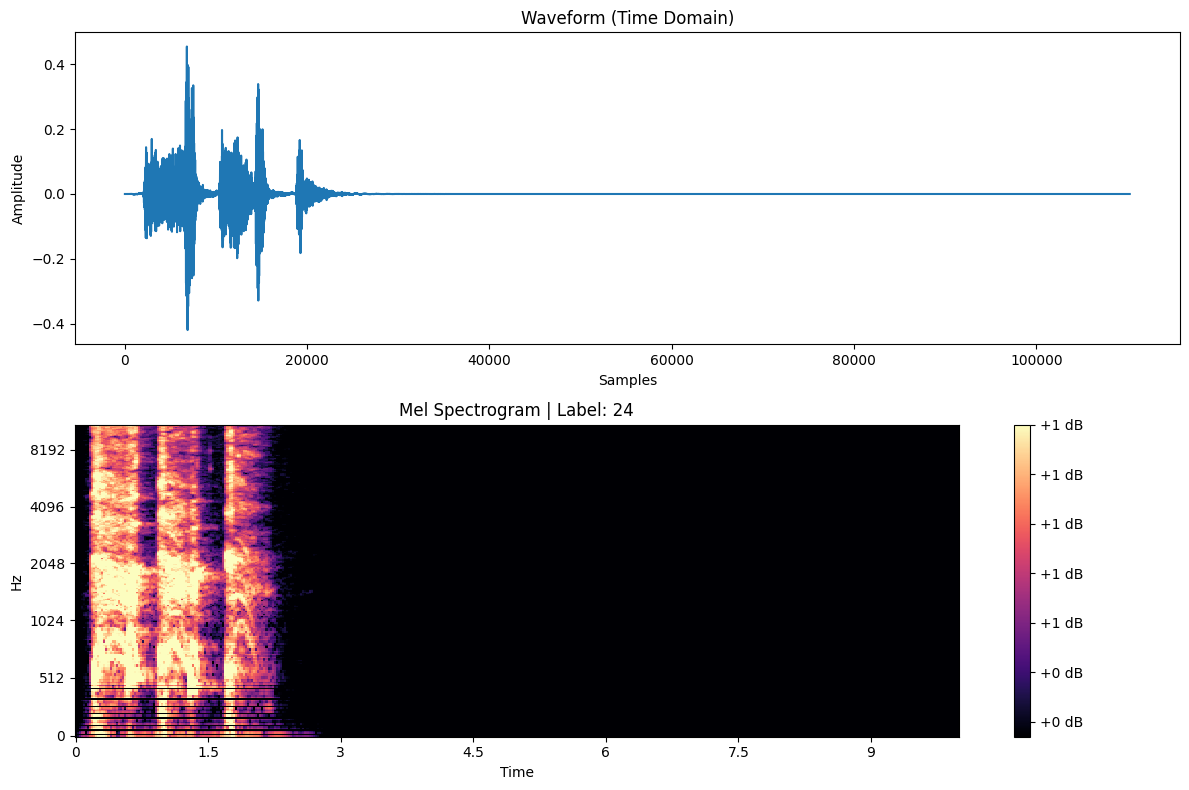

In [9]:
load_spectrum_waveform_foresc50(1000)

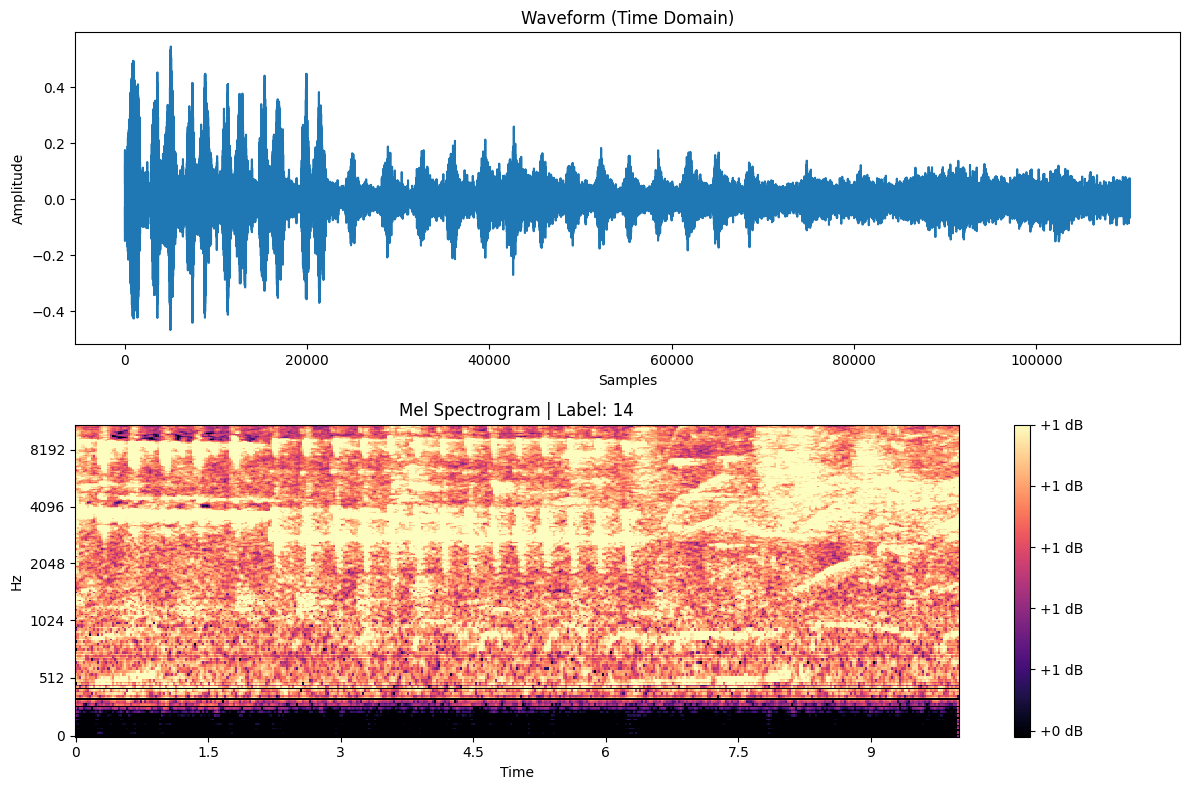

In [13]:
load_spectrum_waveform_foresc50(1)

### Now let's train our model on ESC50 dataset

In [4]:
model = ESC50_CNN()

device = 'cuda' if torch.cuda.is_available() else 'cpu'

cross_validation(
    model=model,
    esc50_dir = ESC_50_MASTER,
    meta_csv = ESC_50_MASTER/"meta/esc50.csv",
    device=device,
    epochs=25,
    batch_size=128,
    fold=5
)

\================= FOLD 1 =================


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


epoch,▁▂▄▅▇█
lr,▁▁▁▁▁▁
train_accuracy,▁▅▅▇▇█
train_loss,█▆▄▂▂▁
val_accuracy,▁▅▃▇▇█
val_loss,█▅▃▂▂▁
epoch,6
lr,0.001
train_accuracy,6.4375
train_loss,3.50304


z:\dlgen-AI-project\.venv\Lib\site-packages\torchaudio\functional\functional.py:584: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (256) may be set too high. Or, the value for `n_freqs` (513) may be set too low.
  warnings.warn(


Loading metadata from file: data\ESC-50-master\meta\esc50.csv
Loading metadata from file: data\ESC-50-master\meta\esc50.csv


z:\dlgen-AI-project\.venv\Lib\site-packages\torch\nn\functional.py:1347: UserWarning: dropout2d: Received a 2-D input to dropout2d, which is deprecated and will result in an error in a future release. To retain the behavior and silence this warning, please use dropout instead. Note that dropout2d exists to provide channel-wise dropout on inputs with 2 spatial dimensions, a channel dimension, and an optional batch dimension (i.e. 3D or 4D inputs).
  warnings.warn(warn_msg)
wandb: WARNING Linked 1 file into the W&B run directory (hardlinks); call wandb.save again to sync new files.


... (27 outputs left out)

Epoch [1/25] Train Loss: 2.7032 | Train Acc: 20.19% | Val Loss: 2.4411 | Val Acc: 30.00%
Epoch [2/25] Train Loss: 2.7281 | Train Acc: 19.94% | Val Loss: 2.5249 | Val Acc: 30.25%
Epoch [3/25] Train Loss: 2.6489 | Train Acc: 22.44% | Val Loss: 2.5273 | Val Acc: 29.50%
Epoch [4/25] Train Loss: 2.6616 | Train Acc: 22.00% | Val Loss: 2.5348 | Val Acc: 29.00%
Epoch [5/25] Train Loss: 2.6753 | Train Acc: 23.06% | Val Loss: 2.5072 | Val Acc: 29.00%
Epoch [6/25] Train Loss: 2.6687 | Train Acc: 22.62% | Val Loss: 2.6046 | Val Acc: 28.25%
Epoch [7/25] Train Loss: 2.6741 | Train Acc: 21.88% | Val Loss: 2.5860 | Val Acc: 29.25%
Epoch [8/25] Train Loss: 2.6798 | Train Acc: 21.44% | Val Loss: 2.5757 | Val Acc: 29.75%
Epoch [9/25] Train Loss: 2.6022 | Train Acc: 23.12% | Val Loss: 2.5650 | Val Acc: 29.00%
Epoch [10/25] Train Loss: 2.6007 | Train Acc: 23.56% | Val Loss: 2.5644 | Val Acc: 29.75%
Epoch [11/25] Train Loss: 2.5805 | Train Acc: 23.75% | Val Loss: 2.5163 | Val Acc: 30.75%
Epoch [12/25] Train

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
lr,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_accuracy,▁▁▄▃▄▄▃▃▅▅▅▃▇▆▅▆▆▅▆▆▅▆▆▆█
train_loss,▇█▅▆▆▆▆▆▄▄▃▆▃▄▄▄▃▄▃▄▂▃▂▁▁
val_accuracy,▄▄▃▂▂▁▂▃▂▃▅▅▅▆▃▂▅▄▂▅█▄▅▅▃
val_loss,▁▅▅▅▄█▇▇▆▆▄▅▅▅▆▆▆▆▇▄▃▅▅▅▅
epoch,25
lr,0.001
train_accuracy,26.25
train_loss,2.52315



========== FINAL RESULT ==========
Fold Accuracies: [13.75, 17.25, 19.25, 27.0, 29.75]
Mean Accuracy: 21.4
Std: 6.024118192731613


# dfs

In [13]:
import torch
from helper.custom_dataloader import GenreDataLoader
from torch.utils.data import DataLoader

dataset = GenreDataLoader(GENRES_STEMS)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

for x, y in loader:
    print(x.shape)
    print(y.shape)
    break

Classes: {'blues': 0, 'classical': 1, 'country': 2, 'disco': 3, 'hiphop': 4, 'jazz': 5, 'metal': 6, 'pop': 7, 'reggae': 8, 'rock': 9}
Total songs: 1000
torch.Size([16, 1, 256, 216])
torch.Size([16])


Number of stems in this song: 4
Genre label: 1
Files:
 [WindowsPath('data/genres_stems/classical/classical.00001/bass.wav'), WindowsPath('data/genres_stems/classical/classical.00001/drums.wav'), WindowsPath('data/genres_stems/classical/classical.00001/other.wav'), WindowsPath('data/genres_stems/classical/classical.00001/vocals.wav')]

STEM 1: bass.wav


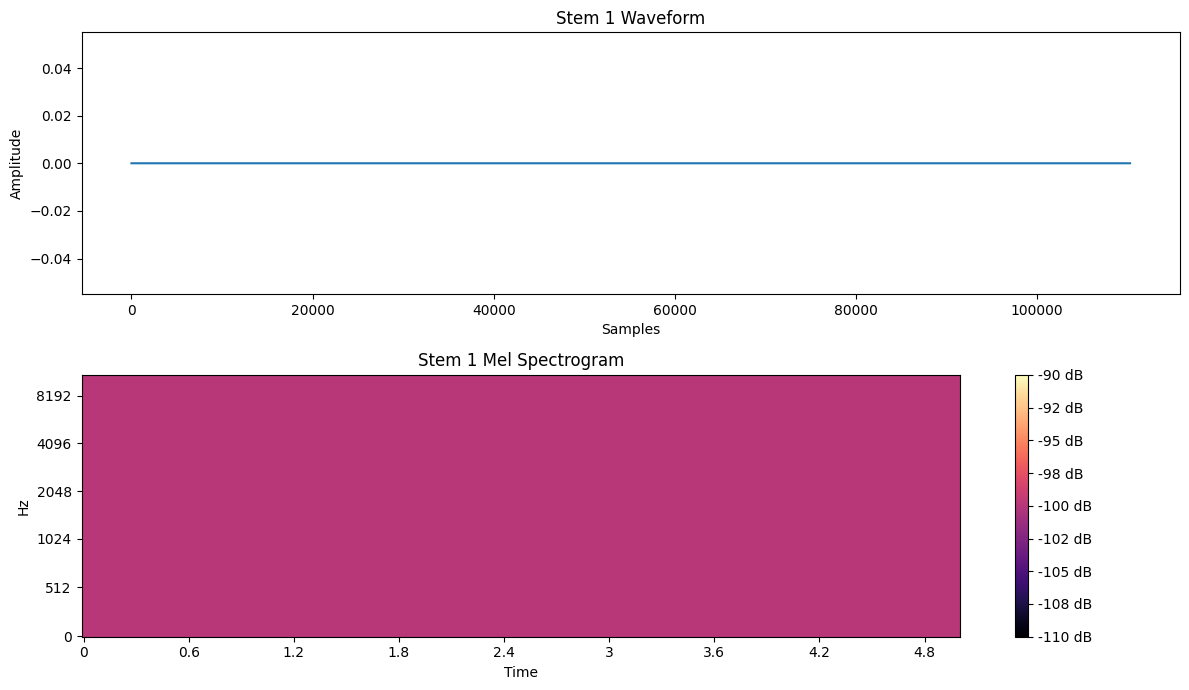

z:\dlgen-AI-project\.venv\Lib\site-packages\IPython\lib\display.py:188: RuntimeWarning: invalid value encountered in divide
  scaled = data / normalization_factor * 32767
z:\dlgen-AI-project\.venv\Lib\site-packages\IPython\lib\display.py:189: RuntimeWarning: invalid value encountered in cast
  return scaled.astype("<h").tobytes(), nchan



STEM 2: drums.wav


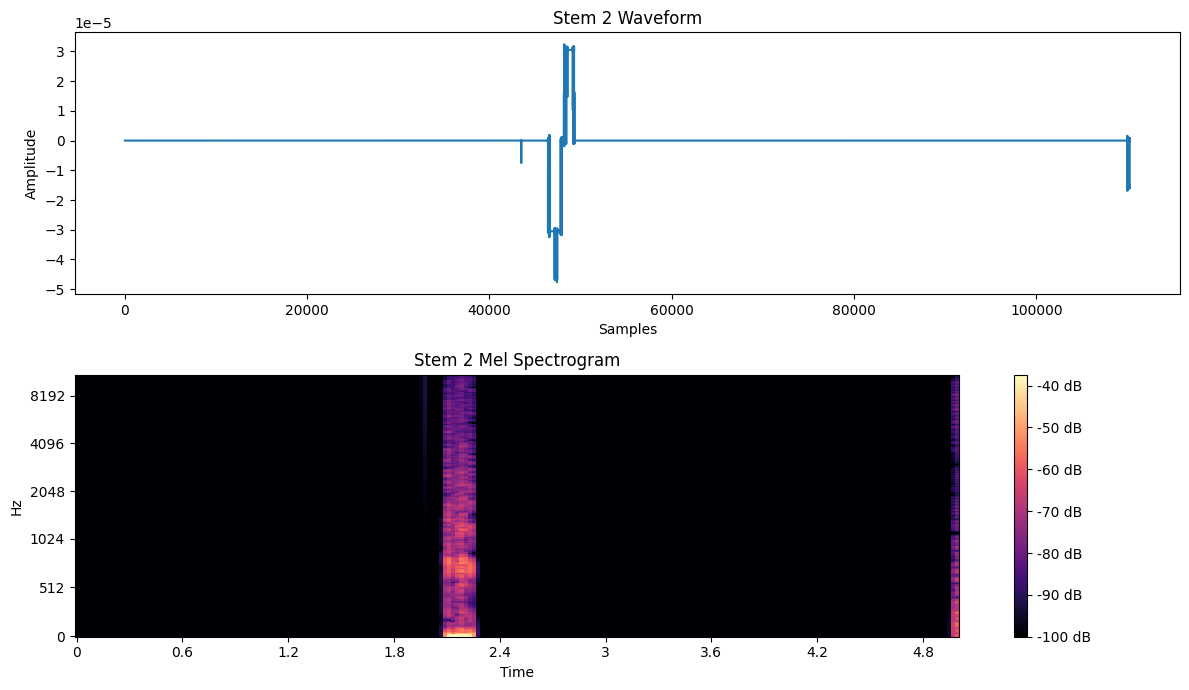


STEM 3: other.wav


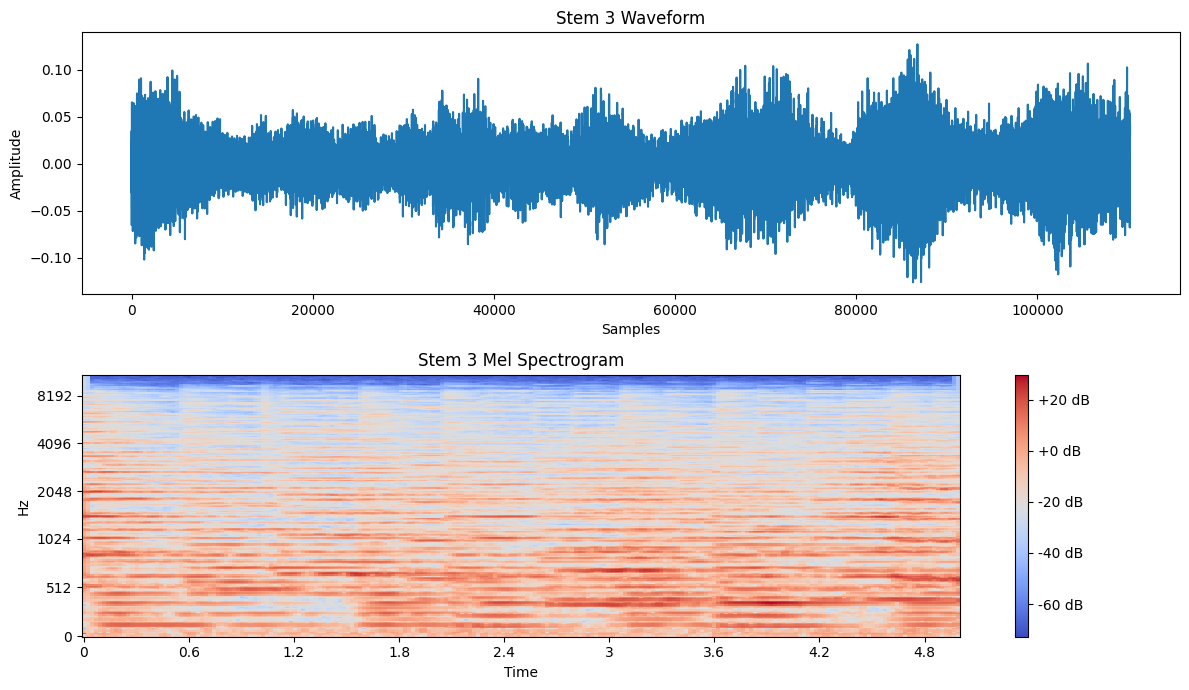


STEM 4: vocals.wav


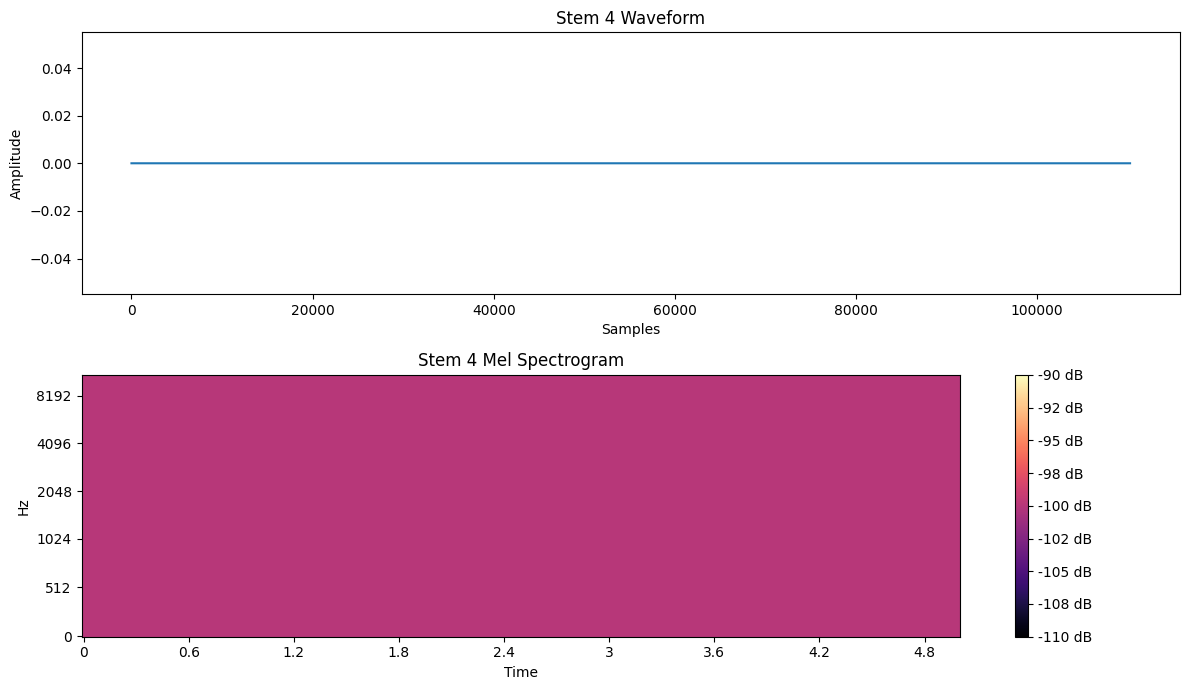


COMBINED SONG (WHAT CNN SEES)


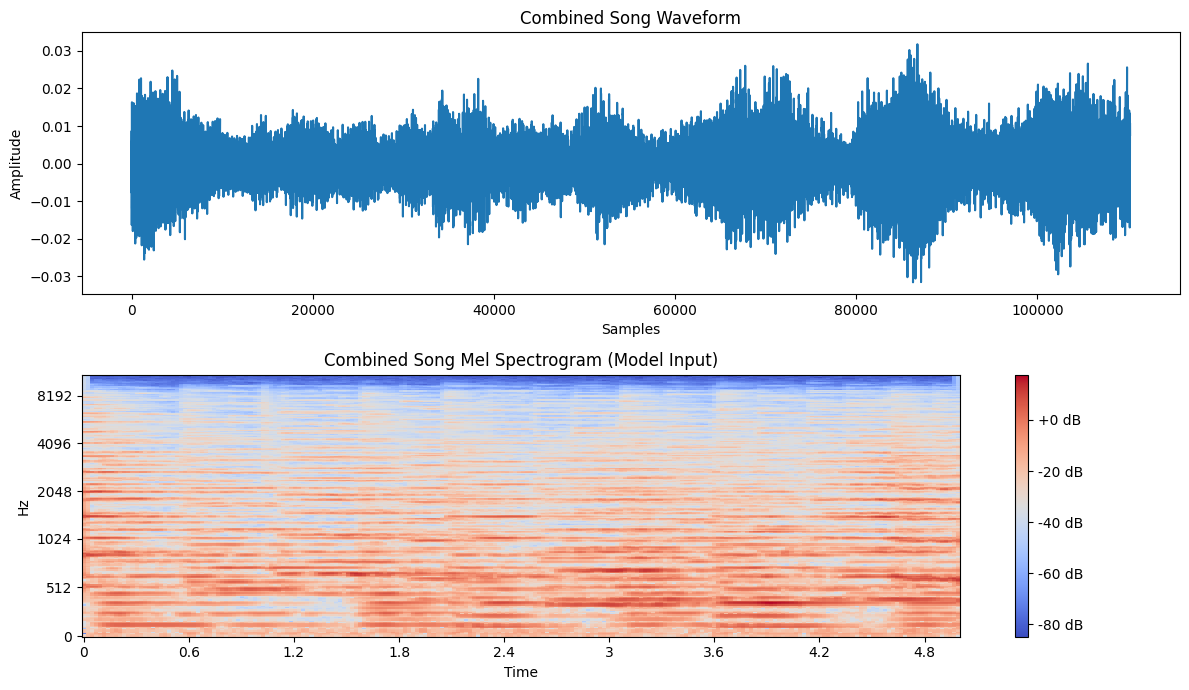

In [17]:
import matplotlib.pyplot as plt
import librosa.display
import torchaudio
import torch
import IPython.display as ipd

idx = 101   # choose any song

variables = dataset.variables
wave_list = dataset.samples[idx]

print("Number of stems in this song:", len(wave_list))
print("Genre label:", dataset.labels[idx])
print("Files:\n", wave_list)

all_waveforms = []

# =========================
# INDIVIDUAL STEMS
# =========================
for i, wav_path in enumerate(wave_list):

    print("\n==============================")
    print(f"STEM {i+1}: {wav_path.name}")
    print("==============================")

    waveform, sr = torchaudio.load(wav_path)

    waveform = waveform.mean(dim=0, keepdim=True)

    if sr != variables.SAMPLE_RATE:
        resampler = torchaudio.transforms.Resample(sr, variables.SAMPLE_RATE)
        waveform = resampler(waveform)

    waveform = variables._fix_length(waveform)

    all_waveforms.append(waveform)

    wave_np = waveform.squeeze(0).detach().cpu().numpy()

    mel = variables.mel(waveform)
    mel = variables.db(mel)
    mel_np = mel.squeeze(0).detach().cpu().numpy()

    fig, axes = plt.subplots(2, 1, figsize=(12, 7))

    # waveform
    axes[0].plot(wave_np)
    axes[0].set_title(f"Stem {i+1} Waveform")
    axes[0].set_xlabel("Samples")
    axes[0].set_ylabel("Amplitude")

    # mel
    img = librosa.display.specshow(
        mel_np,
        sr=variables.SAMPLE_RATE,
        hop_length=512,
        x_axis="time",
        y_axis="mel",
        ax=axes[1]
    )

    axes[1].set_title(f"Stem {i+1} Mel Spectrogram")
    fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

    plt.tight_layout()
    plt.show()

    # play audio
    display(ipd.Audio(wave_np, rate=variables.SAMPLE_RATE))


# =========================
# COMBINED SONG (TRAINING INPUT)
# =========================

print("\n==============================")
print("COMBINED SONG (WHAT CNN SEES)")
print("==============================")

final_waveform = torch.stack(all_waveforms, dim=0).mean(dim=0)
combined_np = final_waveform.squeeze(0).detach().cpu().numpy()

mel = variables.mel(final_waveform)
mel = variables.db(mel)
mel_np = mel.squeeze(0).detach().cpu().numpy()

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

# waveform
axes[0].plot(combined_np)
axes[0].set_title("Combined Song Waveform")
axes[0].set_xlabel("Samples")
axes[0].set_ylabel("Amplitude")

# mel
img = librosa.display.specshow(
    mel_np,
    sr=variables.SAMPLE_RATE,
    hop_length=512,
    x_axis="time",
    y_axis="mel",
    ax=axes[1]
)

axes[1].set_title("Combined Song Mel Spectrogram (Model Input)")
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()

display(ipd.Audio(combined_np, rate=variables.SAMPLE_RATE))